Grid Size : 400 x 800
Start     : (50, 50)
End       : (350, 750)
Running A* pathfinding...
Path found! Length: 924 steps | Nodes visited: 265237
Total Path Cost : 3903.00
Path Length     : 924 pixels


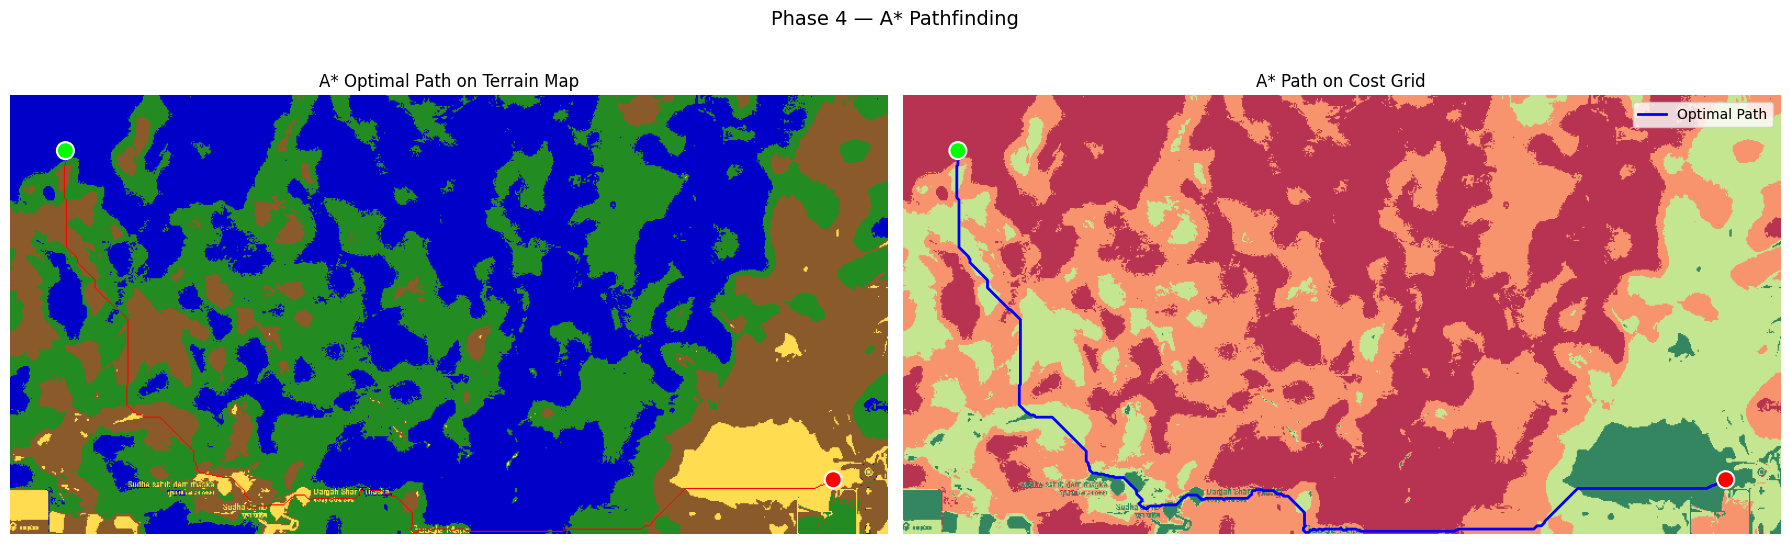

Path saved!


In [ ]:
import numpy as np
import heapq
import matplotlib.pyplot as plt

# ── LOAD DATA ────────────────────────────────────────────
cost_grid   = np.load(r"C:\Users\vinay\OneDrive\Desktop\CODING\path project\input\cost_grid.npy")
terrain_map = np.load(r"C:\Users\vinay\OneDrive\Desktop\CODING\path project\input\terrain_map.npy")

H, W = cost_grid.shape
START = (50, 50)
END   = (350, 750)

print(f"Grid Size : {H} x {W}")
print(f"Start     : {START}")
print(f"End       : {END}")

# ── A* HEURISTIC ─────────────────────────────────────────
def heuristic(a, b):
    # Euclidean distance
    return np.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)

# ── A* ALGORITHM ─────────────────────────────────────────
def astar(cost_grid, start, end):
    H, W = cost_grid.shape
    
    open_set = []
    heapq.heappush(open_set, (0, start))
    
    came_from = {}
    g_score = {start: 0}
    f_score = {start: heuristic(start, end)}
    
    directions = [(-1,0),(1,0),(0,-1),(0,1),
                  (-1,-1),(-1,1),(1,-1),(1,1)]  # 8 directions
    
    visited = 0
    
    while open_set:
        _, current = heapq.heappop(open_set)
        visited += 1
        
        if current == end:
            # Reconstruct path
            path = []
            while current in came_from:
                path.append(current)
                current = came_from[current]
            path.append(start)
            path.reverse()
            print(f"Path found! Length: {len(path)} steps | Nodes visited: {visited}")
            return path
        
        for dr, dc in directions:
            nr, nc = current[0] + dr, current[1] + dc
            
            if 0 <= nr < H and 0 <= nc < W:
                # Diagonal movement costs more
                move_cost = cost_grid[nr, nc]
                if dr != 0 and dc != 0:
                    move_cost *= 1.414
                
                tentative_g = g_score[current] + move_cost
                neighbor = (nr, nc)
                
                if neighbor not in g_score or tentative_g < g_score[neighbor]:
                    came_from[neighbor] = current
                    g_score[neighbor]   = tentative_g
                    f_score[neighbor]   = tentative_g + heuristic(neighbor, end)
                    heapq.heappush(open_set, (f_score[neighbor], neighbor))
    
    print("No path found!")
    return []

# ── RUN A* ───────────────────────────────────────────────
print("Running A* pathfinding...")
path = astar(cost_grid, START, END)

# ── CALCULATE PATH STATS ─────────────────────────────────
if path:
    total_cost = sum(cost_grid[r, c] for r, c in path)
    print(f"Total Path Cost : {total_cost:.2f}")
    print(f"Path Length     : {len(path)} pixels")

# ── VISUALIZE ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: path on terrain map
terrain_display = terrain_map.copy()
for (r, c) in path:
    terrain_display[r, c] = [255, 0, 0]  # red path

axes[0].imshow(terrain_display)
axes[0].scatter([START[1], END[1]], [START[0], END[0]],
                c=['lime', 'red'], s=150, zorder=5, edgecolors='white', linewidths=1.5)
axes[0].set_title("A* Optimal Path on Terrain Map")
axes[0].axis('off')

# Right: path on cost grid
axes[1].imshow(cost_grid, cmap='RdYlGn_r', alpha=0.8)
path_rows = [p[0] for p in path]
path_cols = [p[1] for p in path]
axes[1].plot(path_cols, path_rows, 'b-', linewidth=2, label='Optimal Path')
axes[1].scatter([START[1], END[1]], [START[0], END[0]],
                c=['lime', 'red'], s=150, zorder=5, edgecolors='white', linewidths=1.5)
axes[1].set_title("A* Path on Cost Grid")
axes[1].axis('off')
axes[1].legend()

plt.suptitle("Phase 4 — A* Pathfinding", fontsize=14)
plt.tight_layout()
plt.show()

# ── SAVE PATH ────────────────────────────────────────────
np.save(r"C:\Users\vinay\OneDrive\Desktop\CODING\path project\input\path.npy", np.array(path))
print("Path saved!")